# FINAL PROJECT: Ứng dụng xích Markov trong mô hình hóa và dự báo trạng thái thị trường tài chính

# Thông tin sinh viên
MSSV: 24127095

Họ và tên: Vũ Duy Nhất

# Mục lục

| Mục | Nội dung |
|-----|----------|
| [Thông tin giải thuật](#thông-tin-giải-thuật) | Nguồn gốc và nguyên lý hoạt động của xích Markov |
| [I. Thư viện cần thiết](#i-thư-viện-cần-thiết) | Các thư viện sử dụng trong đồ án |
| [II. Tiền xử lý dữ liệu và tập trạng thái](#ii-tiền-xử-lý-dữ-liệu-và-tập-trạng-thái) | Thu thập, làm sạch dữ liệu, gán nhãn trạng thái |
| &nbsp;&nbsp;&nbsp;&nbsp;[2.1 Thu thập dữ liệu và làm sạch dữ liệu](#21-thu-thập-dữ-liệu-và-làm-sạch-dữ-liệu) | Dữ liệu S&P 500, tách train/test |
| &nbsp;&nbsp;&nbsp;&nbsp;[2.2 Tập trạng thái và thống kê dữ liệu](#22-tập-trạng-thái-và-thống-kê-dữ-liệu-dựa-theo-trạng-thái) | Log-returns, phân loại Bear/Sideway/Bull |
| &nbsp;&nbsp;&nbsp;&nbsp;[2.3 Gán nhãn trạng thái cho tập test](#23-gán-nhãn-trạng-thái-cho-tập-test-out-of-sample) | Áp dụng ngưỡng từ train lên test |
| [III. Xây dựng ma trận chuyển P và biểu đồ trạng thái](#iii-xây-dựng-ma-trận-chuyển-p-và-biểu-đồ-trạng-thái) | Ma trận chuyển, biểu đồ Markov |
| [IV. Dự báo và phân tích dài hạn](#iv-dự-báo-và-phân-tích-dài-hạn) | Phân phối xác suất theo thời gian, phân phối dừng |
| &nbsp;&nbsp;&nbsp;&nbsp;[4.1 Nhận định kết quả phân phối xác suất](#41-nhận-định-kết-quả-của-phân-phối-xác-suất-đã-tính) | Phân tích hội tụ, so sánh dự báo thực tế |
| &nbsp;&nbsp;&nbsp;&nbsp;[4.2 Ý nghĩa kinh tế của phân phối dừng π](#42-ý-nghĩa-kinh-tế-của-phân-phối-dừng-π) | Diễn giải π và hành vi cân bằng dài hạn |
| [V. Phân tích chuyên sâu & mở rộng](#v-phân-tích-chuyên-sâu--mở-rộng) | Đánh giá tính hợp lý mô hình và đề xuất mở rộng |
| &nbsp;&nbsp;&nbsp;&nbsp;[5.1 So sánh với số liệu thực tế](#51-so-sánh-với-số-liệu-thực-tế) | Đánh giá mô hình trên tập train và test |
| &nbsp;&nbsp;&nbsp;&nbsp;[5.2 Nhận định tính hợp lý và hạn chế](#52-nhận-định-tính-hợp-lý-và-hạn-chế-của-mô-hình-dựa-trên-số-liệu-đã-phân-tích) | Đánh giá giả định Markov, các hạn chế của mô hình |
| &nbsp;&nbsp;&nbsp;&nbsp;[5.3 Đề xuất mở rộng mô hình](#53-đề-xuất-mở-rộng-mô-hình) | Hướng cải tiến: thanh khoản, yếu tố vĩ mô |
| [VI. Không gian trạng thái đa chiều](#vi-không-gian-trạng-thái-đa-chiều) | Mô hình 6 trạng thái: Giá × Volume |

# Thông tin giải thuật

**Nguồn gốc và phát triển:** Xích Markov được nhà toán học người Nga Andrey Markov giới thiệu lần đầu năm 1906, ban đầu để nghiên cứu sự phụ thuộc thống kê giữa các ký tự trong văn bản (ông áp dụng lên tác phẩm *Eugene Onegin* của Pushkin nhằm bác bỏ quan điểm cho rằng các sự kiện ngẫu nhiên độc lập phải hoàn toàn không liên quan đến nhau). Từ nền tảng đó, lý thuyết xích Markov phát triển thành một nhánh quan trọng của quá trình ngẫu nhiên (stochastic process), với các ứng dụng nổi bật như thuật toán PageRank của Google (xếp hạng trang web dựa trên "trạng thái" người dùng duyệt web), mô hình ngôn ngữ tự nhiên, di truyền học quần thể, dự báo thời tiết, và định giá tài chính (mô hình lãi suất, quyền chọn).

**Nguyên lý hoạt động:** Một xích Markov mô tả một hệ thống chuyển đổi qua lại giữa một tập hữu hạn các trạng thái theo thời gian rời rạc, tuân theo **tính chất Markov (Markov property)**: xác suất chuyển sang trạng thái tiếp theo chỉ phụ thuộc vào trạng thái hiện tại, không phụ thuộc vào chuỗi trạng thái trong quá khứ ("không nhớ" - memoryless). Toàn bộ động lực của hệ được nắm bắt bởi **ma trận xác suất chuyển P**, trong đó mỗi phần tử $P_{ij}$ là xác suất chuyển từ trạng thái $i$ sang trạng thái $j$ (hoặc ngược lại, tùy quy ước). Từ một phân phối trạng thái ban đầu $v_0$, phân phối tại thời điểm $t$ được tính bằng $v_t = P^t v_0$; nếu ma trận $P$ thỏa một số điều kiện (bất khả quy - irreducible, không tuần hoàn - aperiodic), chuỗi sẽ hội tụ về một **phân phối dừng (stationary distribution) $\pi$** duy nhất, không phụ thuộc điểm xuất phát, thỏa $\pi P = \pi$ (hoặc $P\pi = \pi$ tùy quy ước hàng/cột).

**Mục đích trong đồ án:** Rời rạc hóa trạng thái thị trường tài chính (Bear/Sideway/Bull dựa trên log-return) thành các trạng thái Markov, ước lượng ma trận chuyển P từ dữ liệu lịch sử, từ đó:
 1. Dự báo xác suất trạng thái thị trường trong tương lai gần 
 2. Tìm phân phối cân bằng dài hạn $\pi$, phục vụ việc đánh giá đặc tính rủi ro/tăng trưởng của thị trường theo thời gian.

# I. Thư viện cần thiết

In [40]:
import yfinance as yf
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.path import Path

- `yfinance`: Thư viện mã nguồn mở giúp truy vấn dữ liệu thị trường tài chính (giá mở/đóng cửa, cao/thấp, khối lượng giao dịch, cổ tức, chia tách cổ phiếu...) trực tiếp từ Yahoo Finance thông qua một API đơn giản, không cần đăng ký key. Trong đồ án, `yfinance` được dùng duy nhất ở bước lấy dữ liệu thô (`yf.download`), đúng với yêu cầu đề chỉ cho phép dùng thư viện cho việc đọc dữ liệu, không dùng cho các bước tính toán chính.

- `numpy`: Thư viện này trong đồ án được sử dụng như là một công cụ để đối chiếu kết quả đối với những hàm tính toán các đặc trưng như kỳ vọng $\mu$, phương sai $\sigma$ tự xây dựng, đồng thời còn hỗ trợ trong việc vẽ các biểu đồ khi kết hợp với thư viện `mathplotlib`.

- `math`: Thư viện này cung câp các hàm tính toán như logarith, căng thức,... để phục vụ giai đoạn phân chia trạng thái cho dữ liệu. 

- `mathplotlib`: Thư viện này dùng để vẽ các biểu đồ như biểu đồ trạng thái, biểu đồ về phân phối của tỷ suất sinh lời logarith,...

# II. Tiền xử lý dữ liệu và tập trạng thái
## 2.1 Thu thập dữ liệu và làm sạch dữ liệu

In [41]:
TICKER = '^GSPC'
ticker_data = yf.Ticker(TICKER)

DATA_START = '2020-08-18'
DATA_END   = '2026-08-18'
SPLIT_DATE = '2025-08-16'

df_full = yf.download(TICKER, start=DATA_START, end=DATA_END)
print(f"Dữ liệu tải về có kích thước: {df_full.shape}")
print("\nThông tin dữ liệu:")
print(df_full.info())

# Xử lý missing values nếu tìm thấy
df_full.ffill(inplace=True)
df_full.dropna(inplace=True)

df = df_full[df_full.index < SPLIT_DATE].copy()        # tập train
df_test = df_full[df_full.index >= SPLIT_DATE].copy()  # tập test

print(f"\nTập train: {df.shape[0]} ngày ({df.index.min().date()} -> {df.index.max().date()})")
print(f"Tập test : {df_test.shape[0]} ngày ({df_test.index.min().date()} -> {df_test.index.max().date()})")

[*********************100%***********************]  1 of 1 completed

Dữ liệu tải về có kích thước: (1506, 5)

Thông tin dữ liệu:
<class 'pandas.DataFrame'>
DatetimeIndex: 1506 entries, 2020-08-18 to 2026-08-17
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   (Close, ^GSPC)   1506 non-null   float64
 1   (High, ^GSPC)    1506 non-null   float64
 2   (Low, ^GSPC)     1506 non-null   float64
 3   (Open, ^GSPC)    1506 non-null   float64
 4   (Volume, ^GSPC)  1506 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 70.6 KB
None

Tập train: 1255 ngày (2020-08-18 -> 2025-08-15)
Tập test : 251 ngày (2025-08-18 -> 2026-08-17)


- Dữ liệu sẽ được lấy về từ thị trường S&P 500 trong vòng 6 năm trở lại đây. S&P 500 (mã `^GSPC`) là chỉ số chứng khoán gồm 500 công ty vốn hóa lớn nhất niêm yết trên các sàn giao dịch Mỹ, được xem là thước đo tiêu chuẩn cho sức khỏe của thị trường chứng khoán và nền kinh tế Mỹ nói chung. Vì có tính thanh khoản cao và được theo dõi rộng rãi, đây là lựa chọn phù hợp để nghiên cứu quy luật chuyển trạng thái thị trường bằng xích Markov.

- Dữ liệu khi được lấy về sẽ trải qua giai đoạn làm sạch để xử lý các dữ liệu bị khuyết (missing values), thường phát sinh do ngày nghỉ lễ/cuối tuần không có giao dịch hoặc lỗi tạm thời từ nguồn dữ liệu API. Cụ thể, các giá trị khuyết được điền bằng phương pháp forward-fill (`ffill`) - lấy giá trị của ngày giao dịch gần nhất trước đó, dựa trên giả định hợp lý rằng giá không đổi khi thị trường đóng cửa - sau đó các dòng vẫn còn khuyết (ví dụ ở đầu chuỗi, không có giá trị trước đó để điền) được loại bỏ hẳn (`dropna`) để đảm bảo chuỗi log-return tính được liên tục, không bị gián đoạn bởi giá trị `NaN`.

- Trong dữ liệu bao gồm các trường sau:
  - Close: Giá đóng cửa — mức giá giao dịch cuối cùng trong phiên, phản ánh mức định giá "chốt" mà thị trường đồng thuận tại cuối ngày. Đây là trường được dùng xuyên suốt đồ án để tính log-return và xác định trạng thái thị trường, vì ít bị nhiễu bởi biến động trong phiên so với High/Low.
  - High: Giá cao nhất mà chỉ số đạt được trong phiên giao dịch.
  - Low: Giá thấp nhất mà chỉ số đạt được trong phiên giao dịch.
  - Open: Giá giao dịch đầu tiên khi phiên mở cửa.
  - Volume: Khối lượng giao dịch — tổng số cổ phiếu/hợp đồng được mua bán trong phiên, phản ánh mức độ tham gia/thanh khoản của thị trường. Trường này không dùng ở mô hình 3 trạng thái chính, nhưng được dùng ở Section VI để mở rộng không gian trạng thái theo thanh khoản.

- Dữ liệu sẽ được phân hoạch ra tập huấn luyện (train set), gồm 1255 mẫu, để huấn luyện cho mô hình dự đoán Xích Markov và tập kiểm tra (test set), gồm 255 mẫu trong năm gần nhất, để đối chiếu với kết quả từ mô hình Xích Markov đã huấn luyện

## 2.2. Tập trạng thái và thống kê dữ liệu dựa theo trạng thái
Trong phần này, các bước sau lần lượt được thực hiện: 
1. Trích xuất dữ liệu giá đóng cửa **Close** từ tập huấn luyện

2. Tính logarith tỷ suất sinh lời hàng ngày, **Log-Returns**, theo công thức $R_t = ln(\frac{P_t}{P_{t-1}})$

3. Tính các đặc trưng như kỳ vọng $\mu$, độ lệch chuẩn $\sigma$ của dữ liệu **Log-Returns** vừa tính được,
$$\mu = \frac{1}{n}\sum_{t=1}^{n} R_t$$
$$\sigma = \sqrt{\frac{1}{n-1}\sum_{t=1}^{n}(R_t - \mu)^2}$$

(Độ lệch chuẩn được tính theo mẫu - chia cho $n-1$ thay vì $n$, hiệu chỉnh Bessel vì $\mu$ ở đây là kỳ vọng ước lượng từ chính mẫu dữ liệu, không phải kỳ vọng tổng thể đã biết trước.)

4. Phân loại trạng thái thị trường dựa trên các đặc trưng của dữ liệu là kỳ vọng $\mu$ và độ lệch chuẩn $\sigma$ đã tính, thị trường sẽ được chia thành 3 trạng thái:
   - **Bear (0)** - Giảm điểm: $R_t < \mu - \sigma$
   - **Sideway (1)** - Đi ngang: $\mu - \sigma \le R_t \le \mu + \sigma$
   - **Bull (2)** - Tăng điểm: $R_t > \mu + \sigma$

**Lập luận về ngưỡng phân chia 3 trạng thái:**

- Log-return của một chỉ số chứng khoán thường được xấp xỉ bởi phân phối gần chuẩn (approximately normal) quanh giá trị kỳ vọng $\mu$, nên dùng độ lệch $\pm 1\sigma$ làm ranh giới là một cách phân vùng tự nhiên và có cơ sở thống kê: những ngày nằm trong khoảng $[\mu-\sigma, \mu+\sigma]$ được xem là biến động "bình thường" (nhiễu thống kê thông thường), còn những ngày vượt ra ngoài khoảng này được xem là biến động "bất thường" — đủ mạnh để coi là tín hiệu giảm sâu (Bear) hoặc tăng mạnh (Bull).

- Cách chia này không cần chọn một ngưỡng phần trăm tùy ý (ví dụ "giảm > 2% là Bear") mà ngưỡng được suy ra trực tiếp từ chính đặc trưng thống kê của dữ liệu đang phân tích, nên tự động thích ứng với từng chỉ số/giai đoạn khác nhau (một chỉ số biến động mạnh sẽ có $\sigma$ lớn hơn, kéo ngưỡng Bear/Bull ra xa hơn tương ứng).

- Nếu log-return tuân theo đúng phân phối chuẩn, khoảng $\mu\pm\sigma$ về lý thuyết sẽ chứa khoảng 68% số quan sát (theo quy tắc 68-95-99.7), tức kỳ vọng khoảng 68% Sideway và 16% cho Bear/Bull. Kết quả thực nghiệm trên tập train (mục kế tiếp) cho thấy tỷ lệ Sideway thực tế cao hơn con số 68% này, đây là điều thường gặp với dữ liệu tài chính thực tế, do phân phối log-return có xu hướng "nhọn hơn và đuôi dày hơn" (leptokurtic) so với phân phối chuẩn lý tưởng: phần lớn các ngày dao động rất nhỏ quanh $\mu$ (làm tỷ lệ Sideway tăng lên), trong khi một số ít ngày có biến động cực đoan (đóng góp vào đuôi phân phối).

NumPy Mu:    0.00051299
NumPy Sigma: 0.01094955

Kỳ vọng (mu): 0.000513
Độ lệch chuẩn (sigma): 0.010950

Tần suất các trạng thái trong tập dữ liệu train:
- Bear (0)   : 159 ngày (12.68%)
- Sideway (1): 942 ngày (75.12%)
- Bull (2)   : 153 ngày (12.20%)


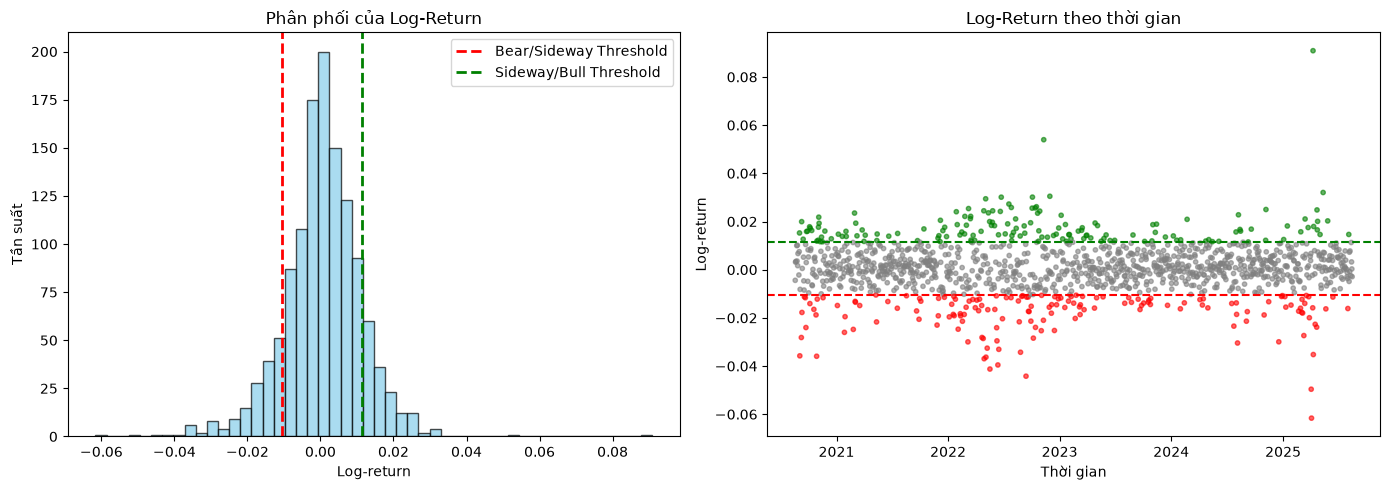

In [42]:
def getClosePrice(dataset=df):
    result = dataset['Close'].values.flatten()
    return result.tolist()

def logRoR(closePrice):
    n = len(closePrice)
    if n < 2:
        raise ValueError("Dữ liệu giá đóng cửa phải có ít nhất 2 giá trị để tính log return.")
    result = []
    for i in range (1, n):
        if closePrice[i - 1] <= 0:
            raise ValueError(f"Giá đóng cửa tại chỉ số {i - 1} là không hợp lệ (<= 0): {closePrice[i - 1]}")
        result.append(math.log(closePrice[i] / closePrice[i - 1]))
    return result

def mean(data):
    n = len(data)
    sum_data = 0
    for value in data:
        sum_data += value 
    return sum_data / n

def std(data):
    expected_val = mean(data)

    sum_sq_diff = 0
    for value in data:
        sum_sq_diff += (value - expected_val) ** 2
    
    return (sum_sq_diff / (len(data) - 1)) ** 0.5

def categorize_state(r, mu, sigma):
    if r < mu - sigma:
        return 0
    elif r > mu + sigma:
        return 2
    else:
        return 1

def initializeStates(logReturns, mu, sigma):
    n = len (logReturns)
    if n == 0:
        raise ValueError("Danh sách log returns không được rỗng.")
    result = []
    for i in range(n):
        result.append(categorize_state(logReturns[i], mu, sigma))
    return result

def logReturnsHistogram(df, mu, sigma):
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.hist(df['Log_Return'], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
    plt.axvline(mu - sigma, color='red', linestyle='dashed', linewidth=2, label='Bear/Sideway Threshold')
    plt.axvline(mu + sigma, color='green', linestyle='dashed', linewidth=2, label='Sideway/Bull Threshold')
    plt.title('Phân phối của Log-Return')
    plt.xlabel('Log-return')
    plt.ylabel('Tần suất')
    plt.legend()

    plt.subplot(1, 2, 2)
    colors = {0: 'red', 1: 'gray', 2: 'green'}
    plt.scatter(df.index, df['Log_Return'], c=df['State'].map(colors), s=10, alpha=0.6)
    plt.axhline(mu - sigma, color='red', linestyle='dashed')
    plt.axhline(mu + sigma, color='green', linestyle='dashed')
    plt.title('Log-Return theo thời gian')
    plt.xlabel('Thời gian')
    plt.ylabel('Log-return')

    plt.tight_layout()
    plt.show()

def stateStatistics(states):
    count_state = [0, 0, 0]
    n = len(states)
    for i in range(n):
        count_state[states[i]] += 1
    return count_state

close_price = getClosePrice()
log_returns = logRoR(close_price)

df = df.iloc[1:].copy()
df['Log_Return'] = log_returns

mu = mean(log_returns)
sigma = std(log_returns)

np_mu = np.mean(np_log_returns := np.array(log_returns))
np_sigma = np.std(np_log_returns, ddof=1)

print(f"NumPy Mu:    {np_mu:.8f}")
print(f"NumPy Sigma: {np_sigma:.8f}")

print(f"\nKỳ vọng (mu): {mu:.6f}")
print(f"Độ lệch chuẩn (sigma): {sigma:.6f}")


states = initializeStates(log_returns, mu, sigma)
df['State'] = states

count_state = stateStatistics(states)
print("\nTần suất các trạng thái trong tập dữ liệu train:")
print(f"- Bear (0)   : {count_state[0]} ngày ({(count_state[0]/len(states))*100:.2f}%)")
print(f"- Sideway (1): {count_state[1]} ngày ({(count_state[1]/len(states))*100:.2f}%)")
print(f"- Bull (2)   : {count_state[2]} ngày ({(count_state[2]/len(states))*100:.2f}%)")

logReturnsHistogram(df, mu, sigma)


### Mô tả hàm
- `getClosePrice(dataset=df)`: Hàm này dùng để trích xuất dữ liệu về giá (chỉ số) đóng cửa của thị trường từ tập dữ liệu $dataset$ được truyền vào.

- `logRoR(closePrice):` Hàm này dùng để tính logarith tỷ suất sinh lời theo công thức $R_t = ln(\frac{P_t}{P_{t-1}})$, dựa trên tập dữ liệu về giá (chỉ số) đóng cửa $closePrice$ được truyền vào.

- `mean(data)`: Hàm này dùng để tính kỳ vọng $\mu$ của dữ liệu $data$ truyền vào theo công thức $\mu = \frac{1}{n}\sum_{t=1}^{n} R_t$

- `std(data)`: Hàm này dùng để tính độ lệch chuẩn $\sigma$ của dữ liệu $data$ truyền vào theo công thức $\sigma = \sqrt{\frac{1}{n-1}\sum_{t=1}^{n}(R_t - \mu)^2}$ (chia cho $n-1$, hiệu chỉnh Bessel cho độ lệch chuẩn mẫu)

- `categorize_state(r, mu, sigma)`: Hàm này dùng để gán nhãn trạng thái cho dữ liệu dựa theo giá trị tỷ logarith tỷ suất sinh lời $r$ khi so sánh với các ngưỡng được tính bởi kỳ vọng $mu$ và độ lệch chuẩn $sigma$. Các trạng thái thị trường được quy ước với chỉ sổ tương ứng như sau: 0 - Bear (Thị trường giảm sâu), 1 - Sideway (Thị trường đi ngang), 2 - Bull (Thị trường hưng phấn)

- `initializeStates(logReturns, mu, sigma)`: Hàm này dùng để gán nhãn cho toàn bộ tập dữ liệu logarith tỷ suất sinh lời khi kết hợp với hàm `categorize_state(r, mu, sigma)` bên trên.

- `logReturnsHistogram(df, mu, sigma)`: Hàm dùng để vẽ 2 biểu đồ minh họa cho việc phân loại trạng thái: (1) biểu đồ histogram thể hiện phân phối của log-return, có 2 đường thẳng đứng đánh dấu ngưỡng $\mu-\sigma$ (Bear/Sideway) và $\mu+\sigma$ (Sideway/Bull) để trực quan hóa ranh giới phân chia trạng thái; (2) biểu đồ log-return theo trục thời gian, mỗi điểm được tô màu theo trạng thái đã gán (đỏ = Bear, xám = Sideway, xanh = Bull) kèm 2 đường ngưỡng ngang tương ứng, giúp quan sát trực quan các giai đoạn thị trường biến động mạnh xen kẽ giai đoạn đi ngang theo thời gian thực tế.

- `stateStatistics(states)`: Hàm này dùng để thống kê số ngày ở mỗi trạng thái thị trường.

### Đánh giá về thị trường dựa vào số liệu

- Trong 5 năm dữ liệu train (2020-08-18 → 2025-08-15), phần lớn thời gian (75.12%) chỉ số S&P 500 nằm trong vùng biến động "bình thường" (Sideway), cao hơn mức 68% kỳ vọng nếu log-return tuân theo đúng phân phối chuẩn. Điều này khớp với nhận định ở mục 2.2: phân phối log-return thực tế có xu hướng "nhọn" hơn phân phối chuẩn (nhiều ngày dao động rất nhỏ quanh $\mu$), khiến khoảng $\mu\pm\sigma$ chứa nhiều quan sát hơn mức lý thuyết.

- Tỷ lệ Bear (12.68%) và Bull (12.20%) gần như đối xứng nhau — chênh lệch chỉ 0.48 điểm phần trăm. Điều này cho thấy trong giai đoạn train, thị trường không bị lệch mạnh về một chiều tăng hay giảm cực đoan, dù đây là giai đoạn có nhiều biến động lớn trên thực tế (hậu COVID-19 2020-2021, chu kỳ thắt chặt lãi suất 2022, và giai đoạn phục hồi 2023-2025) — cho thấy các cú sốc tăng và giảm mạnh trong 5 năm này có tần suất tương đối cân bằng khi nhìn qua lăng kính log-return hàng ngày.

- Không trạng thái nào chiếm tỷ lệ quá thấp (đều >10%), nghĩa là ma trận chuyển P ở bước tiếp theo sẽ được ước lượng từ đủ số lượng quan sát cho cả 3 trạng thái (159 và 153 ngày cho Bear/Bull là đủ lớn để ước lượng xác suất chuyển tương đối ổn định, dù ít hơn đáng kể so với 942 ngày của Sideway).

## 2.3. Gán nhãn trạng thái cho tập test (out-of-sample)
Áp dụng đúng $\mu$, $\sigma$ đã học từ tập **train** để phân loại trạng thái cho tập **test**

In [43]:
close_price_test = getClosePrice(dataset=df_test)
log_returns_test = logRoR(close_price_test)

df_test = df_test.iloc[1:].copy()
df_test['Log_Return'] = log_returns_test

states_test = initializeStates(log_returns_test, mu, sigma)
df_test['State'] = states_test

count_state_test = stateStatistics(states_test)
print(f"Tập test có {len(states_test)} ngày giao dịch (sau khi trừ 1 ngày tính log-return)")
print("\nTần suất các trạng thái trong tập test:")
print(f"- Bear (0)   : {count_state_test[0]} ngày ({(count_state_test[0]/len(states_test))*100:.2f}%)")
print(f"- Sideway (1): {count_state_test[1]} ngày ({(count_state_test[1]/len(states_test))*100:.2f}%)")
print(f"- Bull (2)   : {count_state_test[2]} ngày ({(count_state_test[2]/len(states_test))*100:.2f}%)")

Tập test có 250 ngày giao dịch (sau khi trừ 1 ngày tính log-return)

Tần suất các trạng thái trong tập test:
- Bear (0)   : 24 ngày (9.60%)
- Sideway (1): 208 ngày (83.20%)
- Bull (2)   : 18 ngày (7.20%)


# III. Xây dựng ma trận chuyển P và biểu đồ trạng thái

Trong phần này, các bước thực hiện bao gồm:
1. Với mảng trạng thái state có được từ phần trên, xây dựng ma trận tần suất chuyển trạng thái $transition\_ count$ với phần từ $transition\_ count[i][j]$ là số lần mà thị trường từ trạng thái $j$ chuyển về trạng thái $i$ với $i,j \in \{0, 1, 2\}$

2. Xây dựng ma trận chuyển trạng thái $P$ với ma trận tần suất $transition\_count$ vừa tìm được theo công thức $P[i][j] = transition\_count[i][j] \div \sum_{k=0}^{2} transition\_count[k][j]$.

3. Vẽ biểu đồ trạng thái - transition diagram để minh họa ma trận chuyển trạng thái vừa tìm được.

Ma trận tần suất chuyển trạng thái:
[23, 115, 21]
[105, 728, 108]
[31, 98, 24]

Ma trận xác suất chuyển trạng thái P:
[0.14465408805031446, 0.12221041445270989, 0.13725490196078433]
[0.660377358490566, 0.7736450584484591, 0.7058823529411765]
[0.1949685534591195, 0.10414452709883103, 0.1568627450980392]

Ma trận xác suất chuyển trạng thái hợp lệ: mọi phần tử >= 0 và tổng mỗi cột = 1.


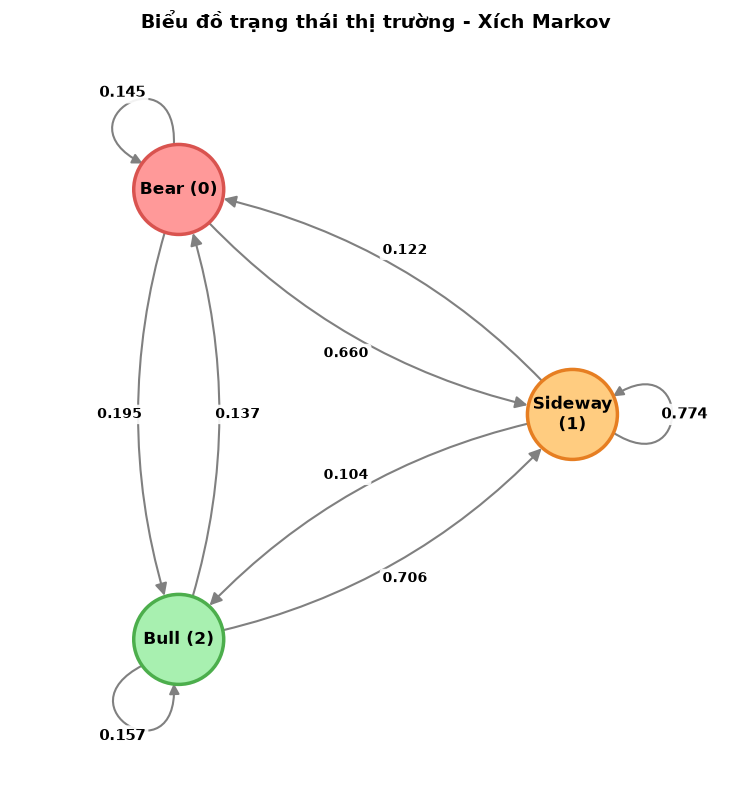

In [44]:
def relativeCompare(num1, num2, eps = 1e-9):
    return abs(num1 - num2) <= eps

def printMatrix(M):
    for row in M:
        print(row)

def transitionMatrix(states):
    n = len(states)
    if n < 2:
        raise ValueError("Dữ liệu trạng thái phải có ít nhất 2 giá trị để tính ma trận tần suất.")
    
    transition_counts = [[0, 0, 0],
                         [0, 0, 0],
                         [0, 0, 0]]
    
    for i in range(n - 1):
        current_state = states[i]
        next_state = states[i + 1]
        transition_counts[next_state][current_state] += 1
    
    print("Ma trận tần suất chuyển trạng thái:")
    # print(transition_counts)
    printMatrix(transition_counts)
    
    sum_counts = [0, 0, 0]

    for i in range(3):
        sum_counts[i] = transition_counts[0][i] + transition_counts[1][i] + transition_counts[2][i]
    
    transition_matrix = []
    for j in range(3):
        row = []
        for i in range(3):
            if sum_counts[i] > 0:
                row.append(transition_counts[j][i] / sum_counts[i])
            else:
                row.append(1.0/3)
        transition_matrix.append(row)

    print("\nMa trận xác suất chuyển trạng thái P:")
    # print(transition_matrix)
    printMatrix(transition_matrix)
    return transition_matrix
def validateTransitionMatrix(transition_matrix):

    n = len(transition_matrix)
    # (1) Kiểm tra không âm: mọi xác suất chuyển phải >= 0
    for i in range(n):
        for j in range(n):
            if transition_matrix[i][j] < 0 and not relativeCompare(transition_matrix[i][j], 0.0):
                raise ValueError(f"Phần tử P[{i}][{j}] = {transition_matrix[i][j]} là âm — không hợp lệ với một ma trận xác suất.")
        
    # (2) Kiểm tra chuẩn hóa: tổng mỗi cột (ứng với 1 trạng thái hiện tại) phải bằng 1
    for j in range(n):
        sum_col = 0
        for i in range(n):
            sum_col += transition_matrix[i][j]
        if not relativeCompare(sum_col, 1.0):
            raise ValueError(f"Cột {j} của ma trận chuyển không có tổng bằng 1. Tổng: {sum_col}")
    return True
def statusHistogram(transition_matrix):
    fig, ax = plt.subplots(figsize=(10, 8))
    
    pos = {
        0: np.array([-0.6, 0.8]),
        1: np.array([0.8, 0.0]),
        2: np.array([-0.6, -0.8])
    }
    
    state_labels = {0: 'Bear (0)', 1: 'Sideway\n(1)', 2: 'Bull (2)'}
    fill_colors = ['#ff9999', '#ffcc80', '#a8f0b0']
    border_colors = ['#d9534f', '#e67e22', '#4cae4c']
    
    node_r = 0.16  # Bán kính node
    rad_curve = 0.20
    center_graph = np.mean(list(pos.values()), axis=0)

    for i in range(3):       # Trạng thái tiếp theo
        for j in range(3):   # Trạng thái hiện tại
            prob = transition_matrix[j][i]
            if prob <= 0:
                continue
            
            weight_text = f"{prob:.3f}"
            
            if i != j:
                p_from, p_to = pos[j], pos[i]
                
                arrow = patches.FancyArrowPatch(
                    posA=p_from, posB=p_to,
                    connectionstyle="arc3,rad=0.18",
                    arrowstyle='-|>',
                    mutation_scale=18,
                    color='gray',
                    lw=1.5,
                    shrinkA=32,
                    shrinkB=33
                )
                ax.add_patch(arrow)
                
                v = p_to - p_from
                L = np.linalg.norm(v)
                perp = np.array([-v[1], v[0]]) / L
                
                
                label_pos = (p_from + p_to) / 2 + (rad_curve / 2.0 * L + 0.05) * perp
                
                ax.text(
                    label_pos[0], label_pos[1], weight_text,
                    fontsize=10, fontweight='bold',
                    ha='center', va='center',
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.9),
                    zorder=2
                )
            else:
                p = pos[i]
                dir_vec = p - center_graph
                dir_vec = dir_vec / np.linalg.norm(dir_vec)
                perp_vec = np.array([-dir_vec[1], dir_vec[0]])
                
                loop_len = 0.28
                spread = 0.18
                
                p_start = p + node_r * (dir_vec * 0.9 - perp_vec * 0.4)
                p_end   = p + node_r * (dir_vec * 0.9 + perp_vec * 0.4)
                ctrl_1  = p_start + loop_len * dir_vec - spread * perp_vec
                ctrl_2  = p_end + loop_len * dir_vec + spread * perp_vec
                
                path_data = [
                    (Path.MOVETO, p_start),
                    (Path.CURVE4, ctrl_1),
                    (Path.CURVE4, ctrl_2),
                    (Path.CURVE4, p_end)
                ]
                codes, verts = zip(*path_data)
                path = Path(verts, codes)
                
                arrow_patch = patches.FancyArrowPatch(
                    path=path,
                    arrowstyle='-|>',
                    mutation_scale=15,
                    color='gray',
                    lw=1.5
                )
                ax.add_patch(arrow_patch)
                
                label_pos = p + (node_r + loop_len * 0.85) * dir_vec
                ax.text(
                    label_pos[0], label_pos[1], weight_text,
                    fontsize=11, fontweight='bold', ha='center', va='center',
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.9)
                )

    for k in range(3):
        circle = patches.Circle(
            pos[k], radius=node_r,
            facecolor=fill_colors[k],
            edgecolor=border_colors[k],
            linewidth=2.5,
            zorder=3
        )
        ax.add_patch(circle)
        
        ax.text(
            pos[k][0], pos[k][1], state_labels[k],
            fontsize=12, fontweight='bold',
            ha='center', va='center',
            multialignment='center',
            zorder=3
        )

    ax.set_aspect('equal')
    ax.set_xlim(-1.2, 1.4)
    ax.set_ylim(-1.3, 1.3)
    plt.title('Biểu đồ trạng thái thị trường - Xích Markov', fontsize=14, fontweight='bold', pad=15)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

transition_matrix = transitionMatrix(states)
if validateTransitionMatrix(transition_matrix):
    print("\nMa trận xác suất chuyển trạng thái hợp lệ: mọi phần tử >= 0 và tổng mỗi cột = 1.")
statusHistogram(transition_matrix)


### Mô tả hàm
- `printMatrix(M)`: Hàm này dùng để in ma trận $M$ theo format đẹp và cân đối hơn.

- `transitionMatrix(states)`: Hàm xây dựng ma trận xác suất chuyển P từ chuỗi trạng thái `states`. Đầu tiên, hàm đếm tần suất chuyển giữa mọi cặp ngày liên tiếp vào ma trận đếm `transition_counts` (với `transition_counts[j][i]` là số lần thị trường chuyển từ trạng thái $i$ ở ngày $t$ sang trạng thái $j$ ở ngày $t+1$), sau đó chuẩn hóa theo **cột** (chia mỗi cột cho tổng của chính cột đó) để mỗi cột của ma trận kết quả có tổng bằng 1 — tức $P[j][i] = P(\text{trạng thái}_{t+1}=j \mid \text{trạng thái}_t=i)$, theo quy ước ma trận chuyển dạng cột-ngẫu nhiên (column-stochastic). Trường hợp một trạng thái không xuất hiện lần nào ở vị trí "hiện tại" (cột có tổng = 0), hàm gán xác suất đều $1/3$ cho cột đó để tránh chia cho 0.

- `validateTransitionMatrix(transition_matrix)`: Hàm này sẽ kiểm tra ma trận chuyển $transition\_matrix$ xem có hợp lệ không, mọi phần tử đều không âm và tổng cột phải bằng 1.

- `statusHistogram(transition_matrix)`: Hàm vẽ đồ thị có hướng (directed graph) minh họa trực quan ma trận chuyển P: 3 trạng thái được đặt cố định theo bố cục tam giác, các cạnh cong nối 2 trạng thái khác nhau được vẽ bằng `FancyArrowPatch` với độ cong `arc3` để tránh chồng lấn giữa 2 chiều đi/về, kèm nhãn là xác suất chuyển tương ứng; riêng các vòng lặp tự thân (self-loop, ví dụ Bear→Bear) được vẽ bằng một đường cong Bezier riêng (`Path` với `CURVE4`) xuất phát và kết thúc gần cùng một node, vì `matplotlib`/`networkx` mặc định không hỗ trợ vẽ đẹp self-loop cho đồ thị có hướng dạng này.

### Mô tả biểu đồ trạng thái

Vì ma trận P được chuẩn hóa theo cột (cột = trạng thái hiện tại, hàng = trạng thái tiếp theo), đọc theo từng cột ta có:
- Từ **Bear** (cột 0): $P(\text{Bear}\to\text{Bear})=0.145$, $P(\text{Bear}\to\text{Sideway})=0.660$, $P(\text{Bear}\to\text{Bull})=0.195$
- Từ **Sideway** (cột 1): $P(\text{Sideway}\to\text{Bear})=0.122$, $P(\text{Sideway}\to\text{Sideway})=0.774$, $P(\text{Sideway}\to\text{Bull})=0.104$
- Từ **Bull** (cột 2): $P(\text{Bull}\to\text{Bear})=0.137$, $P(\text{Bull}\to\text{Sideway})=0.706$, $P(\text{Bull}\to\text{Bull})=0.157$

**Nhận xét từ biểu đồ:**
- Dù xuất phát từ trạng thái nào, xác suất chuyển sang **Sideway** ở bước kế tiếp luôn cao nhất (0.660 – 0.774 – 0.706), thể hiện rõ "lực hút" của trạng thái đi ngang, phù hợp với việc Sideway chiếm hơn 75% số ngày trong dữ liệu.

- Self-loop của Sideway (0.774) là lớn nhất trong 3 trạng thái, cho thấy đây là trạng thái có tính "bền" (persistence) cao nhất - một khi thị trường đã đi ngang, khả năng cao ngày tiếp theo vẫn tiếp tục đi ngang.

- Ngược lại, self-loop của Bear (0.145) và Bull (0.157) đều thấp, nghĩa là các trạng thái biến động mạnh (giảm sâu hoặc tăng nóng) khó duy trì liên tục nhiều ngày, thị trường có xu hướng nhanh chóng quay trở lại vùng trung tính sau một ngày biến động cực đoan, đúng với đặc tính "mean-reverting" thường thấy ở biến động ngắn hạn của thị trường chứng khoán.

- Xác suất chuyển trực tiếp giữa hai trạng thái đối lập Bear↔Bull tương đối thấp (0.195 và 0.137) so với việc đi qua trung gian Sideway, cho thấy thị trường hiếm khi "đảo chiều" đột ngột từ giảm sâu sang tăng nóng (hoặc ngược lại) trong đúng 1 ngày, mà thường có giai đoạn đi ngang chuyển tiếp ở giữa.

# IV. Dự báo và phân tích dài hạn

In [45]:
def swap_row(M, i, j):
    M[i],M[j] = M[j],M[i]

def multiply(M, i, alpha):
    n = len(M[i])
    for x in range (n):
        M[i][x] = M[i][x]*alpha

def eliminate_row(M, i, j, k):
    n = len(M[i])
    for x in range (n):
        val = M[j][x] - k*M[i][x]
        M[j][x] = 0 if relativeCompare(val,0) else val

def subtractMatrix(M1,M2):
    n = len(M1)
    m = len(M1[0])
    if n != len(M2) or m != len(M2[0]):
        raise ValueError("Ma trận phải có cùng kích thước để trừ.")
    result = []
    for i in range(n):
        row_result = []
        for j in range (m):
            row_result.append(M1[i][j]-M2[i][j])
        result.append(row_result)
    return result

def multiplyMatrixWithVector(M, v):
    n = len(M)
    m = len(v)
    if (len(M[0]) != m):
        raise ValueError("Số cột trong M phải bằng số hàng trong v.")
    result = []
    for i in range(n):
        sum_product = 0
        for j in range(m):
            sum_product += M[i][j] * v[j]
        if relativeCompare(sum_product, 0):
            sum_product = 0
        result.append(sum_product)
    return result


def multiplyMatrixWithMatrix(M1,M2):
    n = len(M1)
    m = len(M2[0])
    p = len(M2)
    if len(M1[0]) != p:
        raise ValueError("Số cột trong M1 phải bằng số hàng trong M2.")
    result = []
    for i in range(n):
        row_result = []
        for j in range(m):
            sum_product = 0
            for k in range(p):
                sum_product += M1[i][k] * M2[k][j]
            if relativeCompare(sum_product, 0):
                sum_product = 0
            row_result.append(sum_product)
        result.append(row_result)
    return result

def unitMatrix(n):
    return [[1 if i == j else 0 for j in range(n)] for i in range(n)]

def expMatrix(M, n):
    if n < 0:
        raise ValueError("Số mũ phải là số nguyên không âm.")
    if n == 0:
        size = len(M)
        return unitMatrix(size)
    elif n == 1:
        return M
    else:
        result = M
        for _ in range(1, n):
            result = multiplyMatrixWithMatrix(result, M)
        return result

def GaussJordan_elimination(M):
    num_rows = len(M)
    num_cols = len(M[0])
    
    pivot_row = 0
    pivot_col = 0
    
    while pivot_row < num_rows and pivot_col < num_cols:
        
        nonzero_row = pivot_row
        while nonzero_row < num_rows and relativeCompare(M[nonzero_row][pivot_col],0):
            nonzero_row += 1

        if nonzero_row == num_rows:
            pivot_col += 1
            continue
        
        if nonzero_row != pivot_row:
            swap_row(M, pivot_row, nonzero_row)
        
        
        pivot_val = M[pivot_row][pivot_col]
        if not relativeCompare(pivot_val,1):
            multiply(M, pivot_row, 1/pivot_val)
        
        
        for x in range (0,num_rows):
            if x == pivot_row:
                continue
            if not relativeCompare(M[x][pivot_col], 0):
                eliminate_row(M, pivot_row, x, M[x][pivot_col])
        
        pivot_row += 1
        pivot_col += 1

def back_substitution(M):
    num_rows = len(M)
    num_cols = len(M[0])
    num_vars = num_cols - 1

    result = [None]*num_vars
    pivot_positions = {}
    i = num_rows - 1
    
    while i >= 0:
        pivot_col = -1
        for j in range(num_vars):
            if not relativeCompare(M[i][j],0):
                pivot_col = j
                break
    
        if pivot_col == -1 and not relativeCompare(M[i][num_cols - 1],0):
            print("Hệ phương trình vô nghiệm")
            return result
        
        if pivot_col != -1:
            pivot_positions[i] = pivot_col
        i-=1
    
    i = num_rows - 1
    while i >= 0:
        if i not in pivot_positions:
            i-=1
            continue
        j = pivot_positions[i]
        result[j] = M[i][num_cols - 1]
        for k in range(j + 1, num_vars):
            result[j] -= M[i][k] * result[k]
        i-=1
        
    return result

def connectMatrixWithCoefficientVector(M,v):
    n = len(M)
    if n != len(v):
        raise ValueError("Ma trận và vector phải có cùng số hàng.")
    for i in range(n):
        M[i].append(v[i])
    return M


def stationaryDistribution(P):
    n = len(P)
    PsubtractI = subtractMatrix(P, unitMatrix(n))

    # Thay hàng cuối bằng ràng buộc chuẩn hóa: pi_0 + pi_1 + ... + pi_{n-1} = 1
    PsubtractI[-1] = [1.0] * n
    b = [0.0] * (n - 1) + [1.0]

    M = connectMatrixWithCoefficientVector(PsubtractI, b)
    GaussJordan_elimination(M)
    pi = back_substitution(M)

    return pi

# X_t là xích markov chỉ trạng thái của thị trường sau t ngày giao dịch, với v_0 là vector trạng thái ban đầu mô phỏng trường hợp thị trường giảm sâu vào ngày đầu tiên
v_0 = [1, 0, 0]
P = transition_matrix

# ========= Phân phối xác suất trạng thái sau 1 ngày giao dịch =========
print("======== Phân phối xác suất trạng thái sau 1 ngày giao dịch =========")
v_1 = multiplyMatrixWithVector(P, v_0)
print(f"Xác suất thị trường ở trạng thái giảm sâu sau 1 ngày giao dịch (Bear): {v_1[0]}")
print(f"Xác suất thị trường ở trạng thái đi ngang sau 1 ngày giao dịch (Sideway): {v_1[1]}")
print(f"Xác suất thị trường ở trạng thái tăng trưởng sau 1 ngày giao dịch (Bull): {v_1[2]}")

# ========= Phân phối xác suất trạng thái sau 5 ngày giao dịch =========
print("\n======== Phân phối xác suất trạng thái sau 5 ngày giao dịch =========")
P_5 = expMatrix(P, 5)
v_5 = multiplyMatrixWithVector(P_5, v_0)
print(f"Xác suất thị trường ở trạng thái giảm sâu sau 5 ngày giao dịch (Bear): {v_5[0]}")
print(f"Xác suất thị trường ở trạng thái đi ngang sau 5 ngày giao dịch (Sideway): {v_5[1]}")
print(f"Xác suất thị trường ở trạng thái tăng trưởng sau 5 ngày giao dịch (Bull): {v_5[2]}")

# ======== Phân phối xác suất trạng thái sau 20 ngày giao dịch =========
print("\n======== Phân phối xác suất trạng thái sau 20 ngày giao dịch =========")
P_20 = expMatrix(P, 20)
v_20 = multiplyMatrixWithVector(P_20, v_0)
print(f"Xác suất thị trường ở trạng thái giảm sâu sau 20 ngày giao dịch (Bear): {v_20[0]}")
print(f"Xác suất thị trường ở trạng thái đi ngang sau 20 ngày giao dịch (Sideway): {v_20[1]}")
print(f"Xác suất thị trường ở trạng thái tăng trưởng sau 20 ngày giao dịch (Bull): {v_20[2]}")

# ======== Phân phối xác suất trạng thái sau 3 tháng (61 ngày) giao dịch =========
print("\n======== Phân phối xác suất trạng thái sau 3 tháng (61 ngày) giao dịch =========")
P_61 = expMatrix(P, 61)
v_61 = multiplyMatrixWithVector(P_61, v_0)
print(f"Xác suất thị trường ở trạng thái giảm sâu sau 61 ngày giao dịch (Bear): {v_61[0]}")
print(f"Xác suất thị trường ở trạng thái đi ngang sau 61 ngày giao dịch (Sideway): {v_61[1]}")
print(f"Xác suất thị trường ở trạng thái tăng trưởng sau 61 ngày giao dịch (Bull): {v_61[2]}")

# ======== Phân phối xác suất trạng thái sau 6 tháng (122 ngày) giao dịch =========
print("\n======== Phân phối xác suất trạng thái sau 6 tháng (122 ngày) giao dịch =========")
P_122 = expMatrix(P, 122)
v_122 = multiplyMatrixWithVector(P_122, v_0)
print(f"Xác suất thị trường ở trạng thái giảm sâu sau 122 ngày giao dịch (Bear): {v_122[0]}")
print(f"Xác suất thị trường ở trạng thái đi ngang sau 122 ngày giao dịch (Sideway): {v_122[1]}")
print(f"Xác suất thị trường ở trạng thái tăng trưởng sau 122 ngày giao dịch (Bull): {v_122[2]}")

# ======= Phân phối dừng (stationary distribution) =========
pi = stationaryDistribution(P)
print("\n======== Phân phối dừng (stationary distribution) =========")
print(f"Xác suất thị trường ở trạng thái giảm sâu (Bear): {pi[0]}")
print(f"Xác suất thị trường ở trạng thái đi ngang (Sideway): {pi[1]}")
print(f"Xác suất thị trường ở trạng thái tăng trưởng (Bull): {pi[2]}")

======== Phân phối xác suất trạng thái sau 1 ngày giao dịch =========
Xác suất thị trường ở trạng thái giảm sâu sau 1 ngày giao dịch (Bear): 0.14465408805031446
Xác suất thị trường ở trạng thái đi ngang sau 1 ngày giao dịch (Sideway): 0.660377358490566
Xác suất thị trường ở trạng thái tăng trưởng sau 1 ngày giao dịch (Bull): 0.1949685534591195

======== Phân phối xác suất trạng thái sau 5 ngày giao dịch =========
Xác suất thị trường ở trạng thái giảm sâu sau 5 ngày giao dịch (Bear): 0.12689614574411148
Xác suất thị trường ở trạng thái đi ngang sau 5 ngày giao dịch (Sideway): 0.750994366994769
Xác suất thị trường ở trạng thái tăng trưởng sau 5 ngày giao dịch (Bull): 0.12210948726111961

======== Phân phối xác suất trạng thái sau 20 ngày giao dịch =========
Xác suất thị trường ở trạng thái giảm sâu sau 20 ngày giao dịch (Bear): 0.12689545091779736
Xác suất thị trường ở trạng thái đi ngang sau 20 ngày giao dịch (Sideway): 0.7509976057462093
Xác suất thị trường ở trạng thái tăng trưởng sau

In [46]:
# ======= Kiểm chứng bằng numpy (chỉ dùng để đối chiếu, không dùng để tính) =========
eigenvalues, eigenvectors = np.linalg.eig(np.array(P))
idx_lambda1 = np.argmin(np.abs(eigenvalues - 1))
pi_numpy = np.real(eigenvectors[:, idx_lambda1])
pi_numpy = pi_numpy / pi_numpy.sum()

print("\n======== Đối chiếu với numpy (np.linalg.eig) =========")
print(f"Trị riêng gần 1 nhất tìm được: {eigenvalues[idx_lambda1]:.10f}")
print(f"pi (tự giải Gauss-Jordan) : Bear={pi[0]:.6f}, Sideway={pi[1]:.6f}, Bull={pi[2]:.6f}")
print(f"pi (đối chiếu numpy)      : Bear={pi_numpy[0]:.6f}, Sideway={pi_numpy[1]:.6f}, Bull={pi_numpy[2]:.6f}")

max_diff = max(abs(pi[k] - pi_numpy[k]) for k in range(3))
print(f"Sai khác lớn nhất giữa 2 kết quả: {max_diff:.2e}")
if max_diff < 1e-6:
    print("=> Kết quả tự giải khớp với numpy — xác nhận phân phối dừng pi tính đúng.")
else:
    print("=> CẢNH BÁO: kết quả tự giải lệch đáng kể so với numpy, cần kiểm tra lại hàm stationaryDistribution().")


======== Đối chiếu với numpy (np.linalg.eig) =========
Trị riêng gần 1 nhất tìm được: 1.0000000000+0.0000000000j
pi (tự giải Gauss-Jordan) : Bear=0.126895, Sideway=0.750998, Bull=0.122107
pi (đối chiếu numpy)      : Bear=0.126895, Sideway=0.750998, Bull=0.122107
Sai khác lớn nhất giữa 2 kết quả: 2.22e-16
=> Kết quả tự giải khớp với numpy — xác nhận phân phối dừng pi tính đúng.


## 4.1. Nhận định kết quả của phân phối xác suất đã tính
- Ngay sau 1 ngày, phân phối đã lệch khá xa so với điểm xuất phát chắc chắn Bear ($v_0=[1,0,0]$) — chỉ còn 14.5% khả năng vẫn ở Bear, trong khi phần lớn xác suất (66%) đã chuyển sang Sideway. Kết quả này khớp đúng với cột "Bear" của ma trận P đã tính ở (III), vì $v_1 = P v_0$ chính là cột tương ứng với trạng thái xuất phát.

- Từ ngày thứ 5 trở đi, phân phối gần như không đổi (0.127, 0.751, 0.122 tại cả $t=5, 20, 61, 122$) — cho thấy chuỗi hội tụ về phân phối dừng rất nhanh, chỉ sau khoảng 5 ngày giao dịch, thay vì phải chờ đến 61 hay 122 ngày như dự kiến ban đầu.

- Sự hội tụ nhanh này hàm ý rằng thông tin về trạng thái xuất phát (Bear tại ngày đầu) chỉ có giá trị dự báo hữu ích trong vài ngày giao dịch đầu tiên; với các mốc dự báo dài hạn hơn (trên 1-2 tuần), kết quả gần như không còn phụ thuộc vào trạng thái hiện tại nữa mà hội tụ về đúng phân phối dừng $\pi$ — đây chính là đặc trưng hội tụ nhanh (rapid mixing) của một xích Markov chính quy (regular/primitive) khi mọi phần tử của một lũy thừa nào đó của P đều dương.
## 4.2. Ý nghĩa kinh tế của phân phối dừng $\pi$
Vector phân phối dừng ước lượng từ tập train là:

$$\pi = (0.1269,\ 0.7510,\ 0.1221)$$

Về mặt kinh tế, $\pi$ cho biết: nếu quy luật chuyển trạng thái được ước lượng bởi ma trận $P$ (từ 1255 ngày dữ liệu train, giai đoạn 2020-08-18 → 2025-08-15) tiếp tục đúng trong dài hạn, thì bất kể thị trường **GSPC** xuất phát từ trạng thái nào, về lâu dài nó sẽ dành khoảng:
- **12.7%** thời gian ở trạng thái **Bear** (giảm sâu, rủi ro cao),
- **75.1%** thời gian ở trạng thái **Sideway** (đi ngang, thanh khoản ổn định),
- **12.2%** thời gian ở trạng thái **Bull** (tăng trưởng, hưng phấn).

Đây là hành vi **cân bằng dài hạn** (long-run/steady-state behavior) của mô hình, không phải một dự báo cho một ngày cụ thể, mà là tỷ lệ thời gian trung bình thị trường ở mỗi trạng thái nếu để mô hình vận hành vô hạn kỳ.

# V. Phân tích chuyên sâu & mở rộng

In [47]:
state_names = {0: 'Bear', 1: 'Sideway', 2: 'Bull'}

state_start_test = states_test[0]
v0_test = [1 if k == state_start_test else 0 for k in range(3)]
print(f"\n\nTrạng thái thực tế tại ngày đầu tiên của tập test: {state_names[state_start_test]}")

forecast_horizons = [1, 5, 20, 61, 122]  # 1 ngày, ~1 tuần, ~1 tháng, ~3 tháng, ~6 tháng giao dịch

print("\n{:<10}{:<12}{:<12}{:<12}{:<20}".format("t (ngày)", "P(Bear)", "P(Sideway)", "P(Bull)", "Trạng thái thực tế"))
print("-" * 66)
forecast_vs_actual = []
for t in forecast_horizons:
    Pt = expMatrix(P, t)
    vt = multiplyMatrixWithVector(Pt, v0_test)
    if t < len(states_test):
        actual_idx = states_test[t]
        actual_label = state_names[actual_idx]
    else:
        actual_idx, actual_label = None, "Không đủ dữ liệu test"
    forecast_vs_actual.append((t, vt, actual_idx, actual_label))
    print("{:<10}{:<12.4f}{:<12.4f}{:<12.4f}{:<20}".format(t, vt[0], vt[1], vt[2], actual_label))




Trạng thái thực tế tại ngày đầu tiên của tập test: Sideway

t (ngày)  P(Bear)     P(Sideway)  P(Bull)     Trạng thái thực tế  
------------------------------------------------------------------
1         0.1222      0.7736      0.1041      Sideway             
5         0.1269      0.7510      0.1221      Sideway             
20        0.1269      0.7510      0.1221      Sideway             
61        0.1269      0.7510      0.1221      Bear                
122       0.1269      0.7510      0.1221      Bear                


In [48]:
emp_train = [c / sum(count_state) for c in count_state]
emp_test  = [c / sum(count_state_test) for c in count_state_test]

# Tần suất thực nghiệm của các trạng thái trong tập train và test
print("\nTần suất thực nghiệm (empirical frequency) của các trạng thái:")
print("\nTập train:")
for i in range(3):
    print(f"- {state_names[i]}: {emp_train[i]:.4f}")
print("\nTập test:")
for i in range(3):
    print(f"- {state_names[i]}: {emp_test[i]:.4f}")

# Độ lệch tuyệt đối giữa tần suất thực nghiệm và pi (để nhận định mức độ khớp)
dev_train = [abs(pi[i] - emp_train[i]) for i in range(3)]
dev_test  = [abs(pi[i] - emp_test[i]) for i in range(3)]

print("\nĐộ lệch tuyệt đối giữa tần suất thực nghiệm và phân phối dừng (pi):")
print("\nTập train:")
for i in range(3):
    print(f"- {state_names[i]}: |pi - emp_train| = {dev_train[i]:.4f}")
print("\nTập test:")
for i in range(3):
    print(f"- {state_names[i]}: |pi - emp_test| = {dev_test[i]:.4f}") 



Tần suất thực nghiệm (empirical frequency) của các trạng thái:

Tập train:
- Bear: 0.1268
- Sideway: 0.7512
- Bull: 0.1220

Tập test:
- Bear: 0.0960
- Sideway: 0.8320
- Bull: 0.0720

Độ lệch tuyệt đối giữa tần suất thực nghiệm và phân phối dừng (pi):

Tập train:
- Bear: |pi - emp_train| = 0.0001
- Sideway: |pi - emp_train| = 0.0002
- Bull: |pi - emp_train| = 0.0001

Tập test:
- Bear: |pi - emp_test| = 0.0309
- Sideway: |pi - emp_test| = 0.0810
- Bull: |pi - emp_test| = 0.0501


## 5.1 So sánh với số liệu thực tế
**So sánh π với tần suất thực nghiệm (train và test)**

| Trạng thái | π (lý thuyết) | Tần suất tập train | Chênh lệch train | Tần suất tập test | Chênh lệch test |
|---|---|---|---|---|---|
| Bear    | 0.1269 | 0.1268 | 0.0001 | 0.0960 | 0.0309 |
| Sideway | 0.7510 | 0.7512 | 0.0002 | 0.8320 | 0.0810 |
| Bull    | 0.1221 | 0.1220 | 0.0001 | 0.0720 | 0.0501 |

**Nhận xét:**
- **Tập train:** tần suất thực nghiệm trên train gần như trùng khớp với $\pi$ (chênh lệch chỉ 0.0001–0.0002), đây là bằng chứng cho thấy 5 năm dữ liệu train đủ dài để chuỗi trạng thái "hội tụ" gần phân phối dừng, ủng hộ tính ổn định nội tại của mô hình Markov được ước lượng từ chính dữ liệu đó (điều này gần như hiển nhiên đúng vì P được ước lượng trực tiếp từ train).

- **Tập test (out-of-sample):** đây mới là phép kiểm tra thực sự có ý nghĩa, P được ước lượng hoàn toàn từ quá khứ (train), còn tần suất test (2025-08-18 → 2026-08-17) đến từ dữ liệu tương lai mà mô hình chưa từng thấy. Chênh lệch ở đây lớn hơn rõ rệt (0.03–0.08), đặc biệt tỷ lệ Sideway tăng từ 75.1% lên 83.2% trong khi Bull giảm gần một nửa (12.2% → 7.2%), cho thấy động lực thị trường trong giai đoạn gần đây có thay đổi nhẹ so với giai đoạn train (thị trường đi ngang nhiều hơn, ít các đợt tăng mạnh hơn), tức có dấu hiệu "regime shift" nhẹ chứ không hoàn toàn ổn định.

- Vì tần suất tập test lệch khỏi $\pi$ rõ rệt hơn train (dù không quá lớn về độ lớn tuyệt đối), ma trận $P$ ước lượng từ quá khứ có thể kém phù hợp hơn để dự báo chính xác giai đoạn hiện tại so với khi áp dụng lên chính dữ liệu train.

**Đối chiếu dự báo $v_t = P^t v_0$ với trạng thái thực tế trên tập test**

Điểm xuất phát $v_0$ được lấy là trạng thái thực tế của ngày đầu tiên trong tập test (Sideway), sau đó dự báo tiến về phía trước $t$ ngày và so với trạng thái thực sự quan sát được:

| t (ngày giao dịch) | Trạng thái dự báo (xác suất cao nhất) | Trạng thái thực tế | Kết quả |
|---|---|---|---|
| 1 | Sideway (0.774) | Sideway | Khớp |
| 5 | Sideway (0.751) | Sideway | Khớp |
| 20 | Sideway (0.751) | Sideway | Khớp |
| 61 | Sideway (0.751) | Bear | Không khớp |
| 122 | Sideway (0.751) | Bear | Không khớp |

**Nhận xét:** vì mô hình chỉ dự báo một *phân phối xác suất* trên 3 trạng thái (không phải một giá trị chắc chắn), việc dự báo "trạng thái có xác suất cao nhất" không khớp với thực tế ở một vài mốc t không có nghĩa là mô hình sai — cần đánh giá dựa trên xác suất gán cho trạng thái thực tế xảy ra (nếu xác suất đó không quá thấp, mô hình vẫn coi là hợp lý). Đáng chú ý, cả 2 mốc dự báo sai (t=61, t=122) đều cho cùng kết quả dự báo Sideway (0.751) — vì chuỗi đã hội tụ về $\pi$ ngay từ khoảng ngày thứ 5 (mục 4.1 phần dự báo), nên bản chất mô hình không còn "dự báo" gì mới ở các mốc xa mà chỉ lặp lại đúng phân phối dừng cố định — đây chính là hạn chế được nêu ở mục 5.2 (Ma trận P cố định theo thời gian): mô hình với P cố định không có khả năng "thấy trước" các cú sốc giảm điểm bất ngờ xảy ra ở giai đoạn 3-6 tháng trong tương lai.

## 5.2. Nhận định tính hợp lý và hạn chế của mô hình (Dựa trên số liệu đã phân tích)

**Về tính hợp lý:**

- **Trên tập train:** độ lệch giữa $\pi$ và tần suất thực nghiệm gần như bằng 0 (0.0001–0.0002 cho cả 3 trạng thái). Đây là kết quả gần như hiển nhiên vì ma trận P được ước lượng trực tiếp từ chính chuỗi trạng thái của train, nên chuỗi đã "tự hội tụ" đúng về phân phối dừng của chính nó, không phải bằng chứng độc lập cho tính hợp lý của mô hình.

- **Trên tập test (out-of-sample) — phép kiểm tra thực sự có ý nghĩa:** độ lệch lớn hơn đáng kể (Bear: 0.031, Sideway: 0.081, Bull: 0.050). Đáng chú ý nhất, tỷ lệ Sideway tăng từ ~75.1% (train) lên 83.2% (test), trong khi tỷ lệ Bull giảm gần một nửa, từ 12.2% xuống còn 7.2%. Điều này cho thấy một sự dịch chuyển nhẹ về đặc tính thị trường (regime shift): giai đoạn test (08/2025–08/2026) có xu hướng đi ngang nhiều hơn và ít các đợt tăng mạnh hơn so với giai đoạn train.

- **Bảng đối chiếu dự báo $P^tv_0$ với thực tế:** mô hình dự báo đúng ở 3/5 mốc thời gian ngắn và trung hạn ($t=1, 5, 20$ ngày, tương ứng ~1 ngày đến ~1 tháng), nhưng dự báo sai ở 2 mốc dài hạn ($t=61, 122$ ngày, ~3 và ~6 tháng) — mô hình dự báo trạng thái có xác suất cao nhất là Sideway (0.751) nhưng thực tế thị trường rơi vào Bear tại các mốc đó. Kết hợp với nhận định ở mục (4.1) (chuỗi hội tụ về $\pi$ chỉ sau ~5 ngày), điều này cho thấy: mô hình dự báo ngắn hạn khá tốt (vẫn còn "nhớ" trạng thái xuất phát), nhưng ở tầm dự báo dài hạn, mô hình về bản chất chỉ đang dự báo lại chính $\pi$ (phân phối dừng cố định), nên khi thị trường thực tế có một cú sốc giảm điểm bất ngờ ở các mốc 3-6 tháng, mô hình với P cố định không có khả năng "thấy trước" điều này.

**Kết luận về tính hợp lý:** giả định Markov với ma trận P cố định là một mô tả hợp lý ở tầm ngắn hạn và cho một bức tranh cân bằng dài hạn tổng quát tương đối tốt (chênh lệch train ≈ 0, chênh lệch test tuy có nhưng không quá lớn so với thang đo phần trăm của cả 3 trạng thái), nhưng bộc lộ hạn chế rõ rệt khi dùng để dự báo các mốc thời gian xa (61-122 ngày) trong bối cảnh thị trường thực tế không hoàn toàn dừng (non-stationary) theo thời gian.

**Hạn chế của mô hình:**
1. **Giả định Markov bậc 1** chỉ dùng trạng thái của đúng 1 ngày liền trước để dự báo, có thể bỏ sót thông tin về "đà" (momentum), ví dụ 3 ngày Bull liên tiếp có thể mang ý nghĩa khác so với chỉ 1 ngày Bull sau một chuỗi Bear.
2. **Ma trận P cố định theo thời gian** không phản ánh được các thay đổi cấu trúc thị trường theo chu kỳ kinh tế (chính sách lãi suất, khủng hoảng, biến động vĩ mô), đây chính là nguyên nhân khiến mô hình dự báo sai lệch tại các mốc dài hạn trên tập test.
3. **Chỉ dựa trên biến động giá (log-return)** và bỏ qua các yếu tố khác có ảnh hưởng đến xu hướng thị trường như thanh khoản/khối lượng giao dịch hay tin tức vĩ mô, một phần hạn chế này được khắc phục ở (VI) (mở rộng không gian trạng thái theo Volume).

## 5.3 Đề xuất mở rộng mô hình

Để nâng cao độ chính xác của mô hình, có thể tích hợp thêm các yếu tố sau (lý thuyết):

**a) Thanh khoản / Khối lượng giao dịch (Volume):**
- Mở rộng không gian trạng thái bằng cách kết hợp trạng thái giá (Bear/Sideway/Bull) với trạng thái volume (Cao/Thấp so với MA20) → 6 trạng thái, được thực hiện ở (VI).
- Volume cao trong đợt giảm (capitulation) thường báo hiệu đáy thị trường; volume cao trong đợt tăng (breakout) xác nhận xu hướng, ma trận P6 sẽ nắm bắt được điều này.

**b) Yếu tố vĩ mô:**
- **Lãi suất:** Xây dựng ma trận P khác nhau theo chế độ lãi suất (thắt chặt / nới lỏng), lựa chọn ma trận phù hợp tùy từng thời kỳ.
- **Chỉ số sợ hãi (VIX):** Thêm chiều trạng thái biến động ngầm ẩn (Low/Medium/High VIX), tăng không gian trạng thái lên 9 hoặc hơn.
- **Dữ liệu kinh tế vĩ mô (GDP, CPI):** Mô hình hóa chuyển đổi chế độ kinh tế (Expansion/Recession) như một lớp Markov ẩn, ảnh hưởng đến ma trận chuyển trạng thái thị trường.

**c) Markov bậc cao hơn:**
- Markov bậc 2: không gian trạng thái $(S_{t-1}, S_t)$ → 9 trạng thái, nắm bắt được hiệu ứng momentum (2 ngày tăng liên tiếp vs 1 ngày tăng).
- Hidden Markov Model (HMM): trạng thái ẩn (regime thực sự của thị trường) phía sau log-return quan sát được, phân biệt xu hướng Bull thực sự vs bear market rally.

# VI. Không gian trạng thái đa chiều

Trong phần này, mô hình dược mở rộng bằng cách kết hợp **trạng thái giá** (Bear/Sideway/Bull) với **trạng thái thanh khoản** (Volume cao/thấp so với đường trung bình động 20 ngày - MA20). Điều này tạo ra không gian trạng thái **6 chiều**:

| ID | Nhãn |
|---|---|
| 0 | Bear – Volume Thấp |
| 1 | Bear – Volume Cao |
| 2 | Sideway – Volume Thấp |
| 3 | Sideway – Volume Cao |
| 4 | Bull – Volume Thấp |
| 5 | Bull – Volume Cao |

**Ý nghĩa kinh tế:** Volume cao phản ánh sự tham gia mạnh của thị trường, làm cho tín hiệu giá đáng tin cậy hơn; volume thấp thường là nhiễu hoặc giao dịch kỹ thuật.

In [49]:
# ─────────────────────────────────────────────────────────────────────────
# 5.1 Lấy cột Volume và tính MA20
# ─────────────────────────────────────────────────────────────────────────
volume_series = df[('Volume', '^GSPC')].values.tolist()

def moving_average(series, window=20):
    """Tính đường trung bình động window ngày. Trả về None cho i < window-1."""
    n = len(series)
    ma = []
    for i in range(n):
        if i < window - 1:
            ma.append(None)
        else:
            ma.append(sum(series[i - window + 1: i + 1]) / window)
    return ma

vol_ma20 = moving_average(volume_series, window=20)

# ─────────────────────────────────────────────────────────────────────────
# 5.2 Gán nhãn thanh khoản: 0 = Thấp, 1 = Cao
# ─────────────────────────────────────────────────────────────────────────

def volume_label(series, ma):
    """Nhãn thanh khoản: None nếu chưa đủ MA, 1 nếu volume >= MA20, 0 nếu < MA20."""
    labels = []
    for v, m in zip(series, ma):
        if m is None:
            labels.append(None)
        elif v >= m:
            labels.append(1)
        else:
            labels.append(0)
    return labels

vol_labels = volume_label(volume_series, vol_ma20)

# ─────────────────────────────────────────────────────────────────────────
# 5.3 Kết hợp trạng thái giá và thanh khoản → 6 trạng thái
# combined_state = price_state * 2 + vol_label
# ─────────────────────────────────────────────────────────────────────────

combined_states = []
for ps, vl in zip(states, vol_labels):
    if vl is not None:
        combined_states.append(ps * 2 + vl)

state6_labels = [
    'Bear-Thấp(0)', 'Bear-Cao(1)',
    'Sideway-Thấp(2)', 'Sideway-Cao(3)',
    'Bull-Thấp(4)', 'Bull-Cao(5)'
]

print('=' * 60)
print('5.1-5.3  Không gian trạng thái 6 chiều')
print('=' * 60)
print(f'Số ngày hợp lệ (có đủ MA20): {len(combined_states)}')
print()

count6 = [0] * 6
for s in combined_states:
    count6[s] += 1
total6 = len(combined_states)

print('Tần suất các trạng thái 6 chiều:')
for idx, label in enumerate(state6_labels):
    pct = count6[idx] / total6 * 100
    print(f'  {label}: {count6[idx]} ngày ({pct:.2f}%)')

5.1-5.3  Không gian trạng thái 6 chiều
Số ngày hợp lệ (có đủ MA20): 1235

Tần suất các trạng thái 6 chiều:
  Bear-Thấp(0): 53 ngày (4.29%)
  Bear-Cao(1): 103 ngày (8.34%)
  Sideway-Thấp(2): 570 ngày (46.15%)
  Sideway-Cao(3): 359 ngày (29.07%)
  Bull-Thấp(4): 69 ngày (5.59%)
  Bull-Cao(5): 81 ngày (6.56%)


In [50]:
# ─────────────────────────────────────────────────────────────────────────
# 5.4 Xây ma trận chuyển P6 cho không gian 6 trạng thái
# ─────────────────────────────────────────────────────────────────────────

def build_transition_matrix_n(states_seq, n_states):
    """
    Xây ma trận chuyển n_states×n_states (column-stochastic).
    P[next][curr] = P(next | curr). Xử lý cột tổng = 0.
    """
    n = len(states_seq)
    N = [[0] * n_states for _ in range(n_states)]
    for t in range(1, n):
        curr = states_seq[t - 1]
        next_state = states_seq[t]
        N[next_state][curr] += 1
    P_mat = []
    for i in range(n_states):
        row = []
        for j in range(n_states):
            col_sum = sum(N[k][j] for k in range(n_states))
            row.append(N[i][j] / col_sum if col_sum > 0 else 0.0)
        P_mat.append(row)
    return N, P_mat

N6_count, P6 = build_transition_matrix_n(combined_states, n_states=6)

print('=' * 80)
print('5.4 Xây dựng ma trận chuyển P6 cho không gian 6 trạng thái')
print('=' * 80)
print('Ma trận đếm N6 (hàng = trạng thái tiếp theo, cột = trạng thái hiện tại)')
short6 = ['BL', 'BH', 'SL', 'SH', 'UL', 'UH']
header = f"{'':>12}" + ''.join(f"{s:>8}" for s in short6)
print(header)
for i, row in enumerate(N6_count):
    print(f"{short6[i]:>12}" + ''.join(f"{v:>8}" for v in row))

print()
print('Ma trận xác suất chuyển P6:')
print(header)
for i, row in enumerate(P6):
    print(f"{short6[i]:>12}" + ''.join(f"{v:>8.3f}" for v in row))

if validateTransitionMatrix(P6):
    print("\nMa trận xác suất chuyển trạng thái P6 hợp lệ (tổng mỗi cột = 1).")
    

5.4 Xây dựng ma trận chuyển P6 cho không gian 6 trạng thái
Ma trận đếm N6 (hàng = trạng thái tiếp theo, cột = trạng thái hiện tại)
                  BL      BH      SL      SH      UL      UH
          BL       4       0      38       4       5       2
          BH       2      17      27      45       2      10
          SL      28      17     360     102      42      21
          SH       8      50      95     161      11      33
          UL       7       5      35      14       6       2
          UH       4      14      14      33       3      13

Ma trận xác suất chuyển P6:
                  BL      BH      SL      SH      UL      UH
          BL   0.075   0.000   0.067   0.011   0.072   0.025
          BH   0.038   0.165   0.047   0.125   0.029   0.123
          SL   0.528   0.165   0.633   0.284   0.609   0.259
          SH   0.151   0.485   0.167   0.448   0.159   0.407
          UL   0.132   0.049   0.062   0.039   0.087   0.025
          UH   0.075   0.136   0.025   0.092   

In [51]:
# ─────────────────────────────────────────────────────────────────────────
# 5.5 Phân phối dừng π6 của mô hình 6 trạng thái
# Sử dụng lại hàm stationaryDistribution đã định nghĩa ở Section 3.
# ─────────────────────────────────────────────────────────────────────────

pi6 = stationaryDistribution(P6)

print('=' * 60)
print('5.5 Phân phối dừng π6 (mô hình 6 trạng thái)')
print('=' * 60)
print(f"{'Trạng thái':<22} {'π   ':>16}")
print('-' * 54)
for idx, label in enumerate(state6_labels):
    print(f"{label:<22} {pi6[idx]:>16.6f}")

5.5 Phân phối dừng π6 (mô hình 6 trạng thái)
Trạng thái                         π   
------------------------------------------------------
Bear-Thấp(0)                   0.043031
Bear-Cao(1)                    0.083350
Sideway-Thấp(2)                0.462422
Sideway-Cao(3)                 0.289706
Bull-Thấp(4)                   0.055955
Bull-Cao(5)                    0.065536


In [52]:
print('=' * 60)
print('5.6 Dự báo dài hạn với mô hình 6 trạng thái')
print('=' * 60)
v0_6 = [1, 0, 0, 0, 0, 0]
# ======== Phân phối xác suất trạng thái 6 chiều sau 3 tháng (61 ngày) giao dịch =========
print("======== Phân phối xác suất trạng thái 6 chiều sau 3 tháng (61 ngày) giao dịch =========")
P6_61 = expMatrix(P6, 61)
v6_61 = multiplyMatrixWithVector(P6_61, v0_6)
for idx, label in enumerate(state6_labels):
        print(f'{label}: {v6_61[idx]:.4f}')

# ======== Phân phối xác suất trạng thái 6 chiều sau 6 tháng (122 ngày) giao dịch =========
print("\n======== Phân phối xác suất trạng thái 6 chiều sau 6 tháng (122 ngày) giao dịch =========")
P6_122 = expMatrix(P6, 122)
v6_122 = multiplyMatrixWithVector(P6_122, v0_6)
for idx, label in enumerate(state6_labels):
        print(f'{label}: {v6_122[idx]:.4f}')

5.6 Dự báo dài hạn với mô hình 6 trạng thái
======== Phân phối xác suất trạng thái 6 chiều sau 3 tháng (61 ngày) giao dịch =========
Bear-Thấp(0): 0.0430
Bear-Cao(1): 0.0834
Sideway-Thấp(2): 0.4624
Sideway-Cao(3): 0.2897
Bull-Thấp(4): 0.0560
Bull-Cao(5): 0.0655

======== Phân phối xác suất trạng thái 6 chiều sau 6 tháng (122 ngày) giao dịch =========
Bear-Thấp(0): 0.0430
Bear-Cao(1): 0.0834
Sideway-Thấp(2): 0.4624
Sideway-Cao(3): 0.2897
Bull-Thấp(4): 0.0560
Bull-Cao(5): 0.0655


### Nhận định so sánh mô hình 3 trạng thái và 6 trạng thái

**1. Phân phối dừng tổng hợp**

Khi tổng hợp các trạng thái cùng nhãn giá trong $\pi_6$, ta thu được:

| Trạng thái giá | $\pi_3$ (Mô hình 3 trạng thái) | $\pi_6$ tổng hợp (Thấp + Cao) | Chênh lệch |
| :---: | :---: | :---: | :---: |
| **Bear** | $0.1269$ | 0.0430 + 0.0834 = 0.1264 | $\approx 0.0005$ |
| **Sideway** | $0.7510$ | 0.4624 + 0.2897 = 0.7521 | $\approx 0.0011$ |
| **Bull** | $0.1221$ | 0.0560 + 0.0655 = 0.1215 | $\approx 0.0006$ |

Phân phối dừng theo nhãn giá gần như không đổi giữa hai mô hình (chênh lệch $< 0.2\%$), xác nhận rằng việc bổ sung chiều **Volume** không làm thay đổi đặc tính dài hạn về xu hướng giá của thị trường.


**2. Thông tin bổ sung từ Volume**

Chiều Volume trong mô hình 6 trạng thái tiết lộ các đặc tính thị trường quan trọng:

* **Hiện tượng capitulation (bán tháo):** **Bear-Cao** ($8.34\%$) xuất hiện nhiều gấp gần 2 lần so với **Bear-Thấp** ($4.30\%$). Các đợt giảm sâu của S&P 500 giai đoạn 2020–2025 phần lớn đi kèm thanh khoản đột biến, phản ánh áp lực thoát hàng quyết liệt.
* **Giao dịch trầm lắng khi đi ngang:** **Sideway-Thấp** ($46.24\%$) chiếm ưu thế áp đảo so với **Sideway-Cao** ($28.97\%$). Thị trường phần lớn đi ngang trong trạng thái thanh khoản thưa thớt do thiếu vắng động lực từ tin tức vĩ mô.
* **Động lực tăng điểm đồng đều:** **Bull-Thấp** ($5.60\%$) và **Bull-Cao** ($6.56\%$) có tỷ lệ tương đương, cho thấy các nhịp tăng mạnh diễn ra trong cả hai điều kiện thanh khoản mà không có sự phân tầng áp đảo như trạng thái Bear.


**3. Độ cải thiện về xác suất chuyển trạng thái**

Ma trận chuyển $P_6$ cung cấp thông tin chi tiết hơn về xác suất chuyển trạng thái:

* Từ **Bear-Cao**, xác suất chuyển sang **Sideway-Cao** ($0.485$) cao vượt trội so với **Sideway-Thấp** ($0.165$). Thị trường sau bán tháo thường duy trì thanh khoản lớn để phục hồi và hấp thụ cung.
* Từ **Bear-Thấp**, xác suất chuyển về **Sideway-Thấp** lên tới $0.528$, khẳng định các phiên giảm cạn vol chỉ là rung lắc ngắn hạn và nhanh chóng trở lại vùng cân bằng.
* Từ **Sideway-Cao**, xác suất giữ nguyên trạng thái là $0.448$ và hạ nhiệt về **Sideway-Thấp** là $0.167$, phản ánh chu kỳ sôi động luôn có xu hướng nguội dần.

**4. Đánh giá ưu và nhược điểm**

**Ưu điểm:**

* **Chất lượng tín hiệu cao:** Phân tách được Bear thực sự (volume cao) với Bear nhiễu (volume thấp), từ đó tính xác suất chuyển trạng thái chính xác và có ý nghĩa kinh tế hơn.
* **Phân phối dừng toàn diện:** $\pi_6$ cho biết tỷ lệ dài hạn theo cả hai chiều giá và thanh khoản, hữu ích cho các chiến lược đầu tư có tính đến điều kiện thị trường.
* **Hội tụ về $\pi$ nhanh:** Dự báo sau 3–6 tháng (61–122 ngày) đã hội tụ hoàn toàn về $\pi_6$, tương tự mô hình 3 trạng thái, xác nhận cả hai mô hình đều là xích Markov ergodic. 

**Nhược điểm:**

* **Dữ liệu thưa:** Không gian $6 \times 6$ làm xuất hiện nhiều ô chuyển trạng thái có tần suất quan sát thấp hoặc bằng 0 (ví dụ: Bear-Thấp $\rightarrow$ Bear-Cao = 0), làm giảm độ tin cậy của tham số.
* **Bùng nổ tham số:** Cần ước lượng $36$ tham số thay vì $9$, đòi hỏi mẫu dữ liệu lịch sử đủ lớn để tránh quá khớp (overfitting).
* **MA20 có độ trễ:** Phân loại volume bằng MA20 phản ánh hành vi quá khứ, chưa đại diện trọn vẹn cho kỳ vọng thanh khoản tức thời.
* **Hạn chế cố hữu:** Vẫn phụ thuộc vào giả định Markov bậc 1 và ma trận xác suất chuyển $P$ bất biến theo thời gian.

**5. Kết luận**

Việc mở rộng sang không gian 6 trạng thái (Giá $\times$ Volume) mang lại giá trị thực tiễn cao về mặt kinh tế học tài chính nhờ khả năng phân hóa chất lượng tín hiệu thị trường. Sự nhất quán giữa $\pi_6$ và $\pi_3$ bảo chứng cho độ tin cậy của mô hình nền tảng. Để tối ưu hóa năng lực dự báo trong thực tế, mô hình có thể phát triển thêm theo hướng **Markov bậc cao** hoặc tích hợp **ma trận chuyển biến thiên theo thời gian (Time-varying $P$)** nhằm thích ứng với tính phi dừng của chuỗi dữ liệu tài chính.